# Ageing clock benchmark: GSE41169

Runs six published epigenetic clocks on one public blood-methylation dataset with [Biolearn](https://bio-learn.github.io/) (62 people with schizophrenia, 33 controls) and asks:

1. How well does each clock track chronological age?
2. Do the clocks agree on who is ageing fast?
3. Do they register schizophrenia, a condition linked to shorter life?
4. Does that signal survive adjustment for smoking and blood cell composition?

The framing follows Moqri et al. 2023 (*Cell*, [doi:10.1016/j.cell.2023.08.003](https://doi.org/10.1016/j.cell.2023.08.003)). Run top to bottom; outputs go to `results/`. Interpretation and literature comparison are in `WRITEUP.md`.

In [1]:
# ---- Settings ---------------------------------------------------------------
DATASET = "GSE41169"

# label -> (Biolearn model name, kind). "age" = biological age in years, "pace" = rate of ageing.
CLOCKS = {
    "Horvath":     ("Horvathv1",   "age"),   # trained on chronological age
    "Hannum":      ("Hannum",      "age"),   # trained on chronological age
    "PhenoAge":    ("PhenoAge",    "age"),   # trained on a clinical phenotype
    "GrimAge2":    ("GrimAgeV2",   "age"),   # trained on time to death
    "DunedinPACE": ("DunedinPACE", "pace"),  # trained on pace of physiological decline
    "CausAge":     ("YingCausAge", "age"),   # CpGs with putative causal links to ageing
}
IMPUTATION = "averaging"   # how Biolearn fills CpGs missing from the array

# Metadata coding for this dataset (checked against sample counts and predicted sex)
CONDITION_COL = "disease"
CONDITION_LABELS = {1.0: "control", 2.0: "schizophrenia"}
CASE, CONTROL = "schizophrenia", "control"
SEX_LABELS = {1: "Male", 0: "Female"}

# Samples excluded in the QC-passed analysis, besides sex mismatches (see section 4)
MANUAL_EXCLUDE = ["GSM1009696"]

RESULTS_DIR = "../results"

In [2]:
import sys, platform, subprocess, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

sys.path.insert(0, str(Path("../src").resolve()))
from clockbench import clock_metrics, compare_groups, deviation_correlations, deviation_table
from clockbench.biolearn_io import available_models, find_column, load_dataset, resolve_names, run_clocks
from clockbench.plots import (apply_style, plot_adjustment_effect, plot_deviation_heatmap,
                              plot_group_forest, plot_predicted_vs_age)

import biolearn
from biolearn.model_gallery import ModelGallery

apply_style()
pd.set_option("display.precision", 3)
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 20)
out = Path(RESULTS_DIR)
out.mkdir(parents=True, exist_ok=True)
gallery = ModelGallery()

print("Python", platform.python_version(), "| Biolearn", getattr(biolearn, "__version__", "unknown"))

Python 3.11.18 | Biolearn 0.9.1


## 1. Clocks

In [3]:
models = available_models()
print(f"{len(models)} models in this Biolearn version")

wanted = {label: name for label, (name, _) in CLOCKS.items()}
resolved, missing = resolve_names(list(wanted.values()), models)
for name, close in missing.items():
    print(f"  not found: {name}. Close matches: {close or 'none'}")

clock_names = {label: resolved[name] for label, name in wanted.items() if name in resolved}
kinds = {label: CLOCKS[label][1] for label in clock_names}
print("Will run:", clock_names)

68 models in this Biolearn version
Will run: {'Horvath': 'Horvathv1', 'Hannum': 'Hannum', 'PhenoAge': 'PhenoAge', 'GrimAge2': 'GrimAgeV2', 'DunedinPACE': 'DunedinPACE', 'CausAge': 'YingCausAge'}


## 2. Data

The first run downloads the series matrix from GEO and caches it in the project folder.

In [4]:
t0 = time.perf_counter()
data = load_dataset(DATASET)
print(f"Loaded in {time.perf_counter() - t0:.0f} s")

meta, dnam = data.metadata, data.dnam
meta[CONDITION_COL] = meta[CONDITION_COL].map(CONDITION_LABELS)

AGE_COL = find_column(meta, "age")
SEX_COL = find_column(meta, "sex", "gender")
age = pd.to_numeric(meta[AGE_COL], errors="coerce")
sex01 = meta[SEX_COL].astype(float).rename("sex")
groups = meta[CONDITION_COL].astype("string")
group_order = [CONTROL, CASE]

print(f"Methylation matrix: {dnam.shape[0]:,} CpGs x {dnam.shape[1]} samples")
print(f"Missing beta values per sample: median {dnam.isna().mean().median():.2%}, max {dnam.isna().mean().max():.2%}")
print(f"Age: {age.min():.0f}-{age.max():.0f} y, median {age.median():.0f}\n")

summary_tbl = pd.DataFrame({
    "n": groups.value_counts(),
    "median age": age.groupby(groups).median(),
    "male (%)": (meta[SEX_COL].map(SEX_LABELS) == "Male").groupby(groups).mean().mul(100).round(0),
}).loc[group_order]
summary_tbl

Loaded in 5 s
Methylation matrix: 485,577 CpGs x 95 samples
Missing beta values per sample: median 0.13%, max 0.27%
Age: 18-65 y, median 29



,n,median age,male (%)
disease,,,
control,33,27.0,64.0
schizophrenia,62,31.5,74.0


## 3. Run the clocks

In [5]:
run = run_clocks(data, clock_names, imputation=IMPUTATION)
for label, secs in run.seconds.items():
    print(f"  {label:<12} ok      {secs:5.1f} s")
for label, err in run.failed.items():
    print(f"  {label:<12} FAILED  {err[:160]}")

preds = run.predictions
kinds = {k: v for k, v in kinds.items() if k in preds.columns}

# Age deviation: residual of each clock regressed on chronological age.
# Removes each clock's offset and age bias, so deviations are comparable across clocks.
dev = deviation_table(preds, age)
dev.to_csv(out / "age_deviation_per_sample.csv")
preds.describe().T

  Horvath      ok        0.7 s
  Hannum       ok        0.3 s
  PhenoAge     ok        0.3 s
  GrimAge2     ok        1.0 s
  DunedinPACE  ok        6.5 s
  CausAge      ok        0.5 s


,count,mean,std,min,25%,50%,75%,max
Horvath,95.0,31.944,10.948,8.353,24.787,30.068,36.948,65.402
Hannum,95.0,31.913,11.138,12.446,24.140,30.343,37.333,65.537
PhenoAge,95.0,26.748,12.136,4.248,17.326,25.373,32.639,61.800
GrimAge2,95.0,46.161,11.173,27.187,38.657,44.384,50.270,85.171
DunedinPACE,95.0,0.987,0.127,0.694,0.904,0.984,1.053,1.346
CausAge,95.0,24.930,10.846,2.842,18.314,23.573,30.520,56.129


## 4. Sample QC

Two checks before any group comparison:

- **Sex check.** Methylation-predicted sex against recorded sex. A mismatch means the metadata for that sample can't be trusted.
- **Age outliers.** A sample flagged by several independent clocks at once points to a sample-level problem (e.g. a wrongly recorded age) rather than biology.

In [6]:
sex_pred = gallery.get("SexEstimation").predict(data)
qc = sex_pred.join(meta)
qc["recorded_sex"] = qc[SEX_COL].map(SEX_LABELS)
sex_mismatch = qc.index[qc["predicted_sex"] != qc["recorded_sex"]].tolist()

print(f"Sex mismatches: {len(sex_mismatch)} of {len(qc)}")
qc.loc[sex_mismatch, ["X", "Y", "predicted_sex", "recorded_sex", AGE_COL, CONDITION_COL]].join(dev.round(1))

Sex mismatches: 2 of 95


,X,Y,predicted_sex,recorded_sex,age,disease,Horvath,Hannum,PhenoAge,GrimAge2,DunedinPACE,CausAge
GSM1009739,-34.405,10.245,Male,Female,29.0,control,-2.9,1.6,0.9,0.0,0.0,-0.3
GSM1009749,-34.588,10.347,Male,Female,26.0,control,0.9,-0.5,3.5,-1.9,0.0,4.9


In [7]:
# Most negative age deviation per clock: one sample dominating several clocks is suspicious
extremes = pd.DataFrame({"sample": dev.idxmin(), "deviation": dev.min().round(1)})
display(extremes)

print("Recorded data and deviations for the manually excluded samples:")
display(qc.loc[MANUAL_EXCLUDE, ["predicted_sex", "recorded_sex", AGE_COL, CONDITION_COL]].join(dev.round(1)))

qc_fail = sex_mismatch + [s for s in MANUAL_EXCLUDE if s not in sex_mismatch]
qc_pass = meta.index.difference(qc_fail)
print(f"QC-passed samples: {len(qc_pass)} (excluded: {', '.join(qc_fail)})")

,sample,deviation
Horvath,GSM1009696,-13.6
Hannum,GSM1009696,-16.6
PhenoAge,GSM1009696,-20.6
GrimAge2,GSM1009702,-12.2
DunedinPACE,GSM1009741,-0.2
CausAge,GSM1009696,-17.5


Recorded data and deviations for the manually excluded samples:


,predicted_sex,recorded_sex,age,disease,Horvath,Hannum,PhenoAge,GrimAge2,DunedinPACE,CausAge
GSM1009696,Male,Male,34.0,schizophrenia,-13.6,-16.6,-20.6,-4.0,0.1,-17.5


QC-passed samples: 92 (excluded: GSM1009739, GSM1009749, GSM1009696)


## 5. Agreement with chronological age, and between clocks

Tracking chronological age closely is context, not the goal: a near-perfect age predictor says little about health (the "paradox of biomarkers"). The heatmap asks whether clocks rank the same people as fast agers.

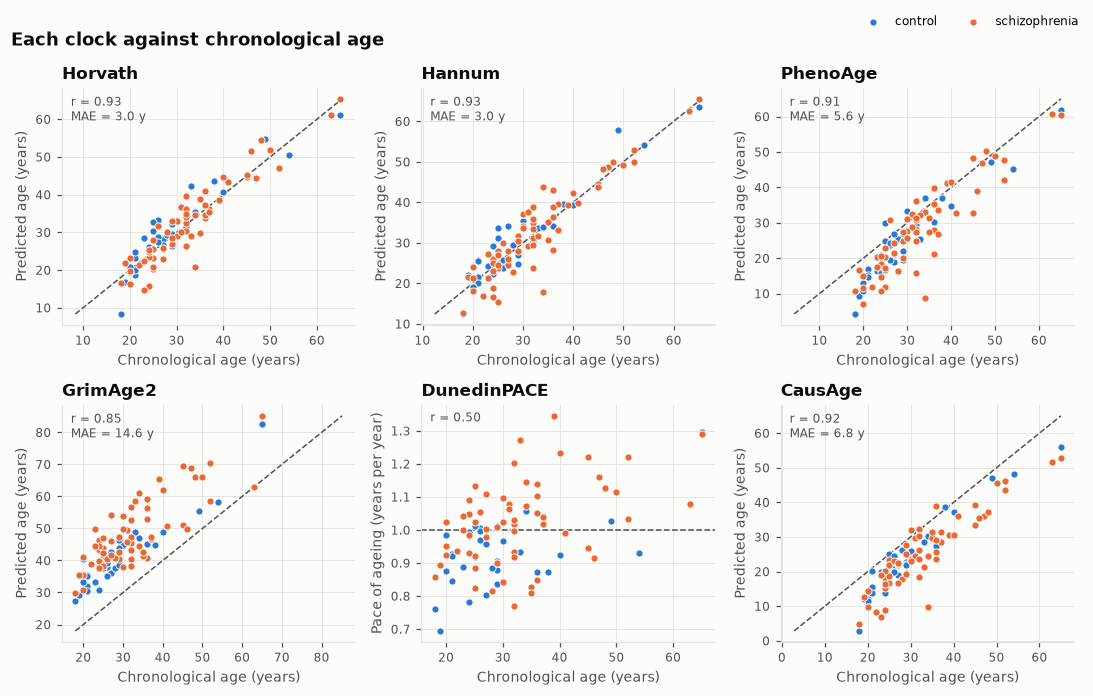

,kind,n,pearson_r,mae_years,median_ae_years,mean_bias_years
clock,,,,,,
Horvath,age,95,0.935,2.955,2.113,0.376
Hannum,age,95,0.929,3.048,1.978,0.345
PhenoAge,age,95,0.912,5.566,4.504,-4.821
GrimAge2,age,95,0.848,14.593,14.406,14.593
DunedinPACE,pace,95,0.502,NaN,NaN,NaN
CausAge,age,95,0.916,6.765,6.198,-6.638


In [8]:
metrics = clock_metrics(preds, age, kinds)
metrics.to_csv(out / "clock_metrics.csv")

fig = plot_predicted_vs_age(preds, age, kinds, metrics=metrics, groups=groups, group_order=group_order)
fig.savefig(out / "fig1_predicted_vs_age.png")
plt.show()
metrics

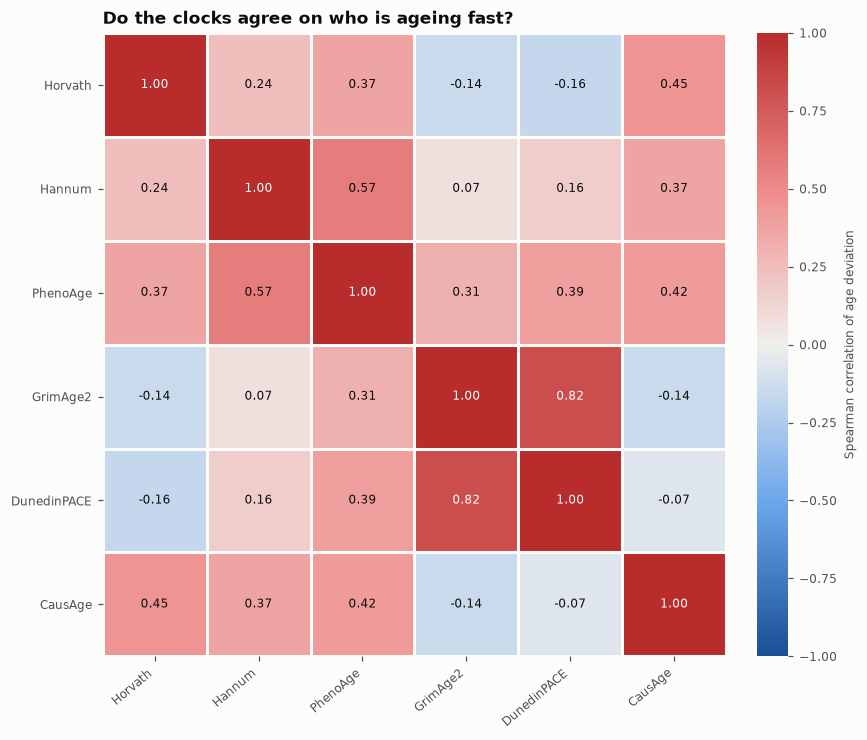

In [9]:
corr = deviation_correlations(dev, method="spearman")
corr.to_csv(out / "age_deviation_correlations.csv")

fig = plot_deviation_heatmap(corr)
fig.savefig(out / "fig2_deviation_correlation.png")
plt.show()

## 6. Schizophrenia vs control

All samples, adjusted for sex. Cohen's d puts clocks with different units (years vs pace) on one scale; q-values are Benjamini-Hochberg across clocks.

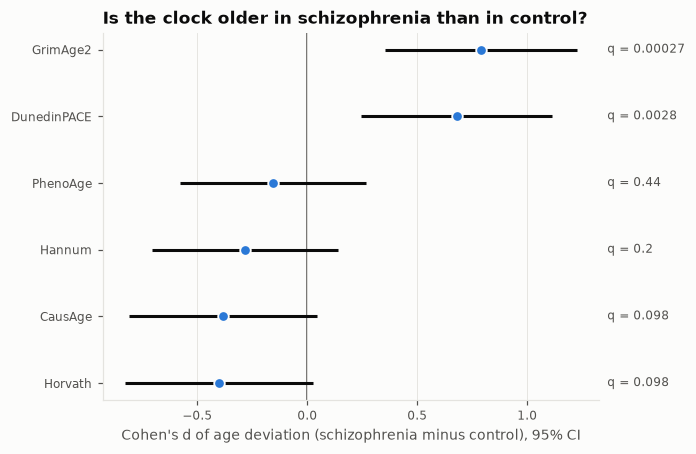

,n_case,n_control,diff,cohens_d,d_ci_low,d_ci_high,diff_adjusted,p_adjusted,q_adjusted
clock,,,,,,,,,
Horvath,62,33,-1.542,-0.402,-0.828,0.024,-1.461,8.274e-02,0.165
Hannum,62,33,-1.168,-0.284,-0.708,0.140,-1.248,1.659e-01,0.199
PhenoAge,62,33,-0.772,-0.155,-0.577,0.268,-0.530,6.198e-01,0.620
GrimAge2,62,33,4.385,0.788,0.351,1.225,4.330,5.644e-04,0.003
DunedinPACE,62,33,0.071,0.678,0.245,1.112,0.074,1.567e-03,0.005
CausAge,62,33,-1.652,-0.383,-0.809,0.042,-1.425,1.224e-01,0.184


In [10]:
res = compare_groups(dev, groups, case=CASE, control=CONTROL, covariates=sex01.to_frame())
res.to_csv(out / "case_control.csv")

fig = plot_group_forest(res, case=CASE, control=CONTROL)
fig.savefig(out / "fig3_case_control_effect.png")
plt.show()
res[["n_case", "n_control", "diff", "cohens_d", "d_ci_low", "d_ci_high", "diff_adjusted", "p_adjusted", "q_adjusted"]]

## 7. Smoking, blood cells and QC exclusions

Smoking is far more common in schizophrenia and is built into GrimAge, so it is the obvious alternative explanation. Smoking is estimated from methylation (no self-report available), and blood cell proportions are estimated by deconvolution. NK cells are left out (estimated near zero in every sample) and neutrophils are the reference type, since proportions sum to 1.

In [11]:
smoking = gallery.get("SmokingMcCartney").predict(data)["Predicted"].rename("smoking")
cells = gallery.get("DeconvoluteBlood450K").predict(data)
cellcov = cells[["b_cell", "cd4_t_cell", "cd8_t_cell", "monocyte"]]

print("Smoking score by group:")
display(smoking.groupby(groups).agg(["mean", "median", "std"]).round(2).loc[group_order])
print("Mean blood cell proportions by group:")
display(cells.groupby(groups).mean().round(3).loc[group_order])

Smoking score by group:


,mean,median,std
disease,,,
control,3.14,2.79,0.93
schizophrenia,4.39,4.60,1.37


Mean blood cell proportions by group:


,neutrophil,nk_cell,b_cell,cd4_t_cell,cd8_t_cell,monocyte
disease,,,,,,
control,0.657,0.038,0.042,0.142,0.070,0.051
schizophrenia,0.662,0.023,0.044,0.157,0.065,0.049


In [12]:
# Sensitivity of the unadjusted effect (Cohen's d) to the excluded samples
sample_sets = {
    "all": meta.index,
    "without outlier": meta.index.difference(MANUAL_EXCLUDE),
    "QC-passed": qc_pass,
}
d_table = pd.DataFrame({
    name: compare_groups(deviation_table(preds.loc[keep], age.loc[keep]), groups, CASE, CONTROL)["cohens_d"]
    for name, keep in sample_sets.items()
})
print("Cohen's d, schizophrenia minus control:")
d_table.round(2)

Cohen's d, schizophrenia minus control:


,all,without outlier,QC-passed
clock,,,
Horvath,-0.40,-0.37,-0.41
Hannum,-0.28,-0.24,-0.24
PhenoAge,-0.15,-0.10,-0.08
GrimAge2,0.79,0.80,0.82
DunedinPACE,0.68,0.67,0.72
CausAge,-0.38,-0.35,-0.33


In [13]:
# Nested covariate models, on all samples and on QC-passed samples
covariate_sets = {
    "sex": [sex01],
    "sex+smoking": [sex01, smoking],
    "sex+smoking+cells": [sex01, smoking, cellcov],
}
rows = []
for sample_set in ["all", "QC-passed"]:
    keep = sample_sets[sample_set]
    d = deviation_table(preds.loc[keep], age.loc[keep])   # residuals refit on each sample set
    for name, parts in covariate_sets.items():
        r = compare_groups(d, groups, CASE, CONTROL, covariates=pd.concat(parts, axis=1))
        rows.append(r[["n_case", "n_control", "diff_adjusted", "se_adjusted", "p_adjusted"]]
                    .assign(samples=sample_set, model=name).reset_index())

adjusted = pd.concat(rows, ignore_index=True)
adjusted.to_csv(out / "case_control_adjusted.csv", index=False)

print("Difference in age deviation, schizophrenia minus control (years; pace units for DunedinPACE):")
display(adjusted.pivot(index="clock", columns=["samples", "model"], values="diff_adjusted").round(2))
print("p-value:")
display(adjusted.pivot(index="clock", columns=["samples", "model"], values="p_adjusted").map(lambda p: f"{p:.2g}"))

Difference in age deviation, schizophrenia minus control (years; pace units for DunedinPACE):


samples       all                               QC-passed                              
model         sex sex+smoking sex+smoking+cells       sex sex+smoking sex+smoking+cells
clock                                                                                  
CausAge     -1.43       -0.94             -0.93     -1.20       -0.57             -0.45
DunedinPACE  0.07        0.00              0.01      0.08       -0.00              0.00
GrimAge2     4.33       -0.57             -0.25      4.55       -1.00             -0.67
Hannum      -1.25       -1.12             -1.00     -0.99       -0.72             -0.53
Horvath     -1.46       -0.92             -0.87     -1.42       -0.84             -0.69
PhenoAge    -0.53       -1.22             -0.92     -0.23       -0.92             -0.55

p-value:


samples          all                               QC-passed                              
model            sex sex+smoking sex+smoking+cells       sex sex+smoking sex+smoking+cells
clock                                                                                     
CausAge         0.12        0.36              0.38      0.17        0.56              0.65
DunedinPACE   0.0016        0.86              0.48    0.0013        0.92              0.82
GrimAge2     0.00056        0.38              0.69   0.00044        0.13              0.29
Hannum          0.17        0.26              0.26      0.24        0.45              0.52
Horvath        0.083        0.32              0.36      0.08        0.35              0.46
PhenoAge        0.62         0.3              0.42      0.82        0.42               0.6

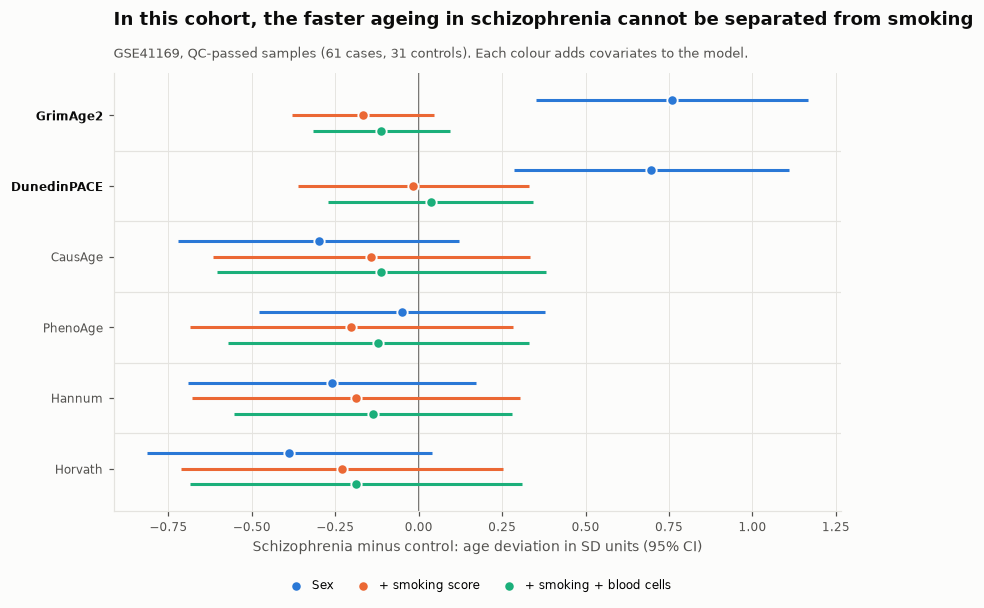

In [14]:
# Figure 4: the same models on QC-passed samples, in SD units so years and pace are comparable
d_sd = deviation_table(preds.loc[qc_pass], age.loc[qc_pass])
d_sd = d_sd / d_sd.std()
labels = {"sex": "Sex", "sex+smoking": "+ smoking score", "sex+smoking+cells": "+ smoking + blood cells"}
effects = {labels[name]: compare_groups(d_sd, groups, CASE, CONTROL, covariates=pd.concat(parts, axis=1))
           for name, parts in covariate_sets.items()}

order = [c for c in ["Horvath", "Hannum", "PhenoAge", "CausAge", "DunedinPACE", "GrimAge2"] if c in d_sd.columns]
n_case, n_ctrl = (int(v) for v in effects["Sex"].loc[order[0], ["n_case", "n_control"]])

fig = plot_adjustment_effect(
    effects, order,
    title="In this cohort, the faster ageing in schizophrenia cannot be separated from smoking",
    subtitle=f"{DATASET}, QC-passed samples ({n_case} cases, {n_ctrl} controls). Each colour adds covariates to the model.",
    xlabel="Schizophrenia minus control: age deviation in SD units (95% CI)",
    highlight={"GrimAge2", "DunedinPACE"},
)
fig.savefig(out / "fig4_adjustment_effect.png")
plt.show()

## 8. Environment

In [15]:
freeze = subprocess.run([sys.executable, "-m", "pip", "freeze"], capture_output=True, text=True).stdout
(out / "environment.txt").write_text(f"dataset={DATASET}\nimputation={IMPUTATION}\n\n" + freeze)
print("Wrote", sorted(p.name for p in out.iterdir() if p.name != ".gitkeep"))

Wrote ['age_deviation_correlations.csv', 'age_deviation_per_sample.csv', 'agent_runs', 'case_control.csv', 'case_control_adjusted.csv', 'clock_metrics.csv', 'coloc_serpine1_parental_longevity.csv', 'environment.txt', 'fig1_predicted_vs_age.png', 'fig2_deviation_correlation.png', 'fig3_case_control_effect.png', 'fig4_adjustment_effect.png', 'fig5_target_ranking.png', 'fig5_target_ranking_v1.png', 'mr_pilot_checks.csv', 'mr_pilot_exposures.csv', 'mr_pilot_instruments.csv', 'mr_pilot_results.csv', 'opengwas_outcome_candidates.csv', 'opengwas_pqtl_candidates.csv', 'phewas_rs2227631.csv', 'replication_rs2227631.csv', 'target_ranking.csv', 'target_ranking_v1.csv', 'target_rankingv1.csv', 'target_report.md', 'target_report_v1.md']
